In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

In [2]:
from skbio.stats.composition import clr, clr_inv, ilr, ilr_inv
from jax.scipy.optimize import minimize as jmin
from scipy.optimize import minimize, least_squares
from scipy import stats
import optimistix

In [3]:
from emu_example import simple_net, clr_func, clr_inv_func, aitchison, objective_wssr, objective_clr_wssr, calc_ci

In [4]:
solver = optimistix.BFGS(
    rtol=1e-12, atol=1e-12, verbose=frozenset({"step"})
)

In [5]:
# Defining the true fluxes 
M = jnp.array([[-1,-1,2], 
               [0,0,-1], 
               [-1,0,1]])
v1 = 100 
v3 = 50
v5 = 20
v_free = jnp.array([v1,v3,v5]) 
v2, v4, v6 = -M @ v_free

v_true = jnp.array([v1,v2,v3,v4,v5,v6])

# Defining an array with the free fluxes. 
params = jnp.array([v3, v5], dtype=float)
n_params = len(params)

# Define the true MID for the example- 
data = simple_net(params, v1=v1)
print(np.round(data,4))

[1.000e-04 8.008e-01 1.983e-01 9.000e-04]


# Data simulation

In [ ]:
# Making simulated data. 
total_mol = 1e5
total_isos = total_mol*data
rng = np.random.default_rng(seed=1234)

sims = 1000
norm_sigma = total_isos*0.2  # 0.1 is ~10% CV, 0.2 is ~20 % CV
norm_sim = rng.normal(total_isos, norm_sigma, size=(sims,4))

df = pl.from_numpy(norm_sim, schema=["m0", "m1", "m2", "m3"])
df.insert_column(column=(pl.col("m0")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m0_com"), index=4)
df.insert_column(column=(pl.col("m1")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m1_com"), index=5)
df.insert_column(column=(pl.col("m2")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m2_com"), index=6)
df.insert_column(column=(pl.col("m3")/(pl.col("m0")+pl.col("m1")+pl.col("m2")+pl.col("m3"))).alias("m3_com"), index=7)

m0,m1,m2,m3,m0_com,m1_com,m2_com,m3_com
f64,f64,f64,f64,f64,f64,f64,f64
4.312588,81102.765861,22766.734625,91.602119,0.000041,0.780094,0.218984,0.000881
7.446024,126730.16812,13963.980501,105.697297,0.000053,0.900026,0.099171,0.000751
4.233479,85581.341792,17796.36609,112.422381,0.000041,0.826918,0.171955,0.001086
5.256787,88395.997747,14811.372914,50.504195,0.000051,0.856027,0.143433,0.000489
6.901249,107835.231623,21891.274882,71.072608,0.000053,0.830751,0.168648,0.000548
…,…,…,…,…,…,…,…
6.558849,69756.332399,16525.395098,78.174451,0.000076,0.807678,0.19134,0.000905
5.805935,74867.360577,14569.852529,95.776967,0.000065,0.836144,0.162721,0.00107
6.752878,76327.116683,20289.002826,95.61063,0.00007,0.789168,0.209774,0.000989


In [7]:
f123_sim = jnp.array([statistics.mean(df["m0_com"]), statistics.mean(df["m1_com"]), statistics.mean(df["m2_com"]), statistics.mean(df["m3_com"])])

D_sim = jnp.array([[statistics.stdev(df["m0_com"]),0,0,0], [0,statistics.stdev(df["m1_com"]),0,0], [0,0,statistics.stdev(df["m2_com"]),0], [0,0,0,statistics.stdev(df["m3_com"])]])

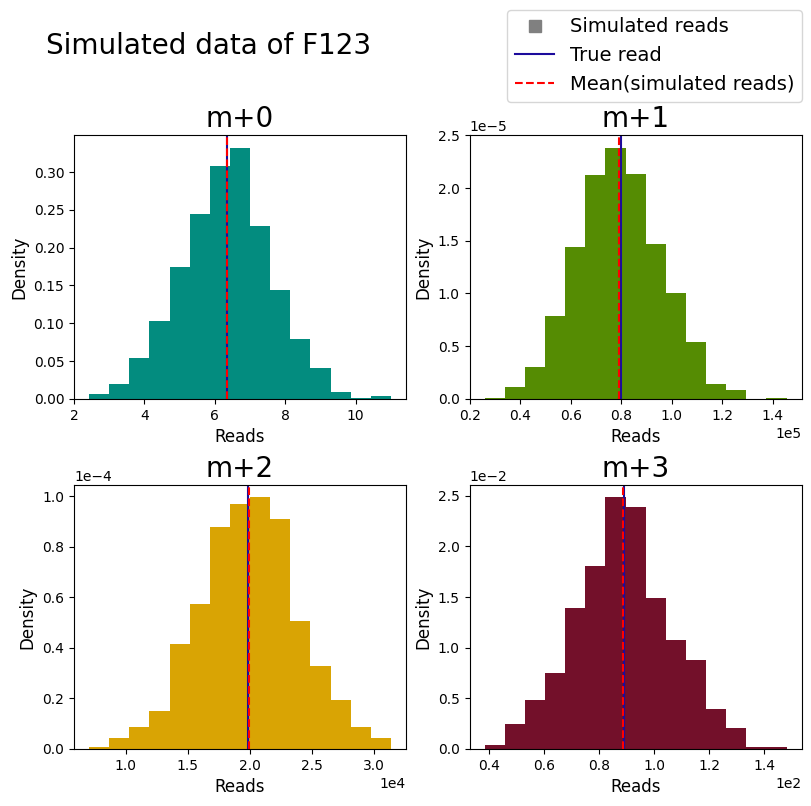

In [130]:
colors =["#73102A", "#038C7F", "#558C03", "#F2CB05", "#D9A404", "#1C0B9C"]

fig, ((ax1, ax2),(ax3,ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(8,8), layout="constrained")
ax1.hist(df["m0"].to_numpy(), bins=15, density=True, label="Simulated m+0", color=colors[1])
ax2.hist(df["m1"].to_numpy(), bins=15, density=True, label="Simulated m+1", color=colors[2])
ax3.hist(df["m2"].to_numpy(), bins=15, density=True, label="Simulated m+2", color=colors[4])
ax4.hist(df["m3"].to_numpy(), bins=15, density=True, label="Simulated m+3", color=colors[0])

ax1.axvline(total_isos[0], color=colors[5], label="True")
ax2.axvline(total_isos[1], color=colors[5], label="True")
ax3.axvline(total_isos[2], color=colors[5], label="True")
ax4.axvline(total_isos[3], color=colors[5], label="True")

total_mean = jnp.array([statistics.mean(df["m0"]), statistics.mean(df["m1"]), statistics.mean(df["m2"]), statistics.mean(df["m3"])])

ax1.axvline(total_mean[0], color="red", linestyle="dashed", label="Mean")
ax2.axvline(total_mean[1], color="red", linestyle="dashed", label="Mean")
ax3.axvline(total_mean[2], color="red", linestyle="dashed", label="Mean")
ax4.axvline(total_mean[3], color="red", linestyle="dashed", label="Mean")


ax1.set_title("m+0", size=20)
ax2.set_title("m+1", size=20)
ax3.set_title("m+2", size=20)
ax4.set_title("m+3", size=20)

ax1.set_xlabel("Reads", size=12)
ax2.set_xlabel("Reads", size=12)
ax3.set_xlabel("Reads", size=12)
ax4.set_xlabel("Reads", size=12)

ax1.set_ylabel("Density", size=12)
ax2.set_ylabel("Density", size=12)
ax3.set_ylabel("Density", size=12)
ax4.set_ylabel("Density", size=12)

ax1.ticklabel_format(scilimits=(-2,2))
ax2.ticklabel_format(scilimits=(-2,2))
ax3.ticklabel_format(scilimits=(-2,2))
ax4.ticklabel_format(scilimits=(-2,2))

# Custom legend
custom_marker = [
    Line2D([0], [0], color="gray", marker="s", linestyle="", markersize=8),
    Line2D([0], [0], color=colors[5], marker="", linestyle="-", markersize=8),
    Line2D([0], [0], color="red", marker="", linestyle="dashed", markersize=8)
]
fig.legend(custom_marker, ["Simulated reads", "True read", "Mean(simulated reads)"], fontsize=14, loc="outside upper right")

fig.suptitle("Simulated data of F123", size=20, x=0.05, y=0.96, ha="left")

plt.show()

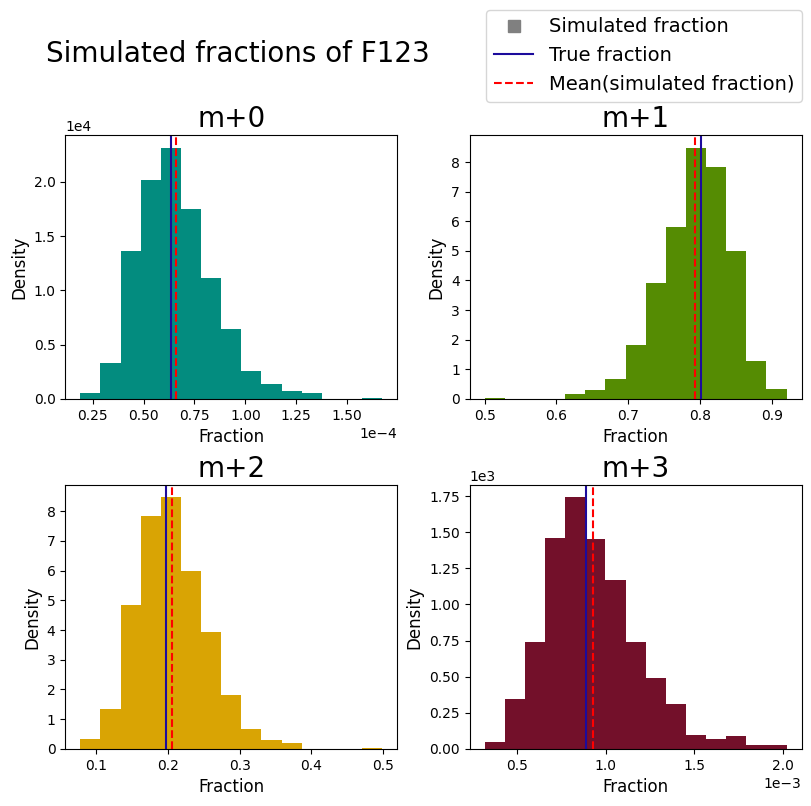

In [131]:
fig, ((ax1, ax2),(ax3,ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(8,8), layout="constrained")
ax1.hist(df["m0_com"].to_numpy(), bins=15, density=True, label="Simulated m0", color=colors[1])
ax2.hist(df["m1_com"].to_numpy(), bins=15, density=True, label="Simulated m1", color=colors[2])
ax3.hist(df["m2_com"].to_numpy(), bins=15, density=True, label="Simulated m2", color=colors[4])
ax4.hist(df["m3_com"].to_numpy(), bins=15, density=True, label="Simulated m3", color=colors[0])

ax1.axvline(data[0], color=colors[5], label="True")
ax2.axvline(data[1], color=colors[5], label="True")
ax3.axvline(data[2], color=colors[5], label="True")
ax4.axvline(data[3], color=colors[5], label="True")

ax1.axvline(f123_sim[0], color="red", linestyle="dashed", label="Mean")
ax2.axvline(f123_sim[1], color="red", linestyle="dashed", label="Mean")
ax3.axvline(f123_sim[2], color="red", linestyle="dashed", label="Mean")
ax4.axvline(f123_sim[3], color="red", linestyle="dashed", label="Mean")

ax1.set_title("m+0", size=20)
ax2.set_title("m+1", size=20)
ax3.set_title("m+2", size=20)
ax4.set_title("m+3", size=20)

ax1.set_xlabel("Fraction", size=12)
ax2.set_xlabel("Fraction", size=12)
ax3.set_xlabel("Fraction", size=12)
ax4.set_xlabel("Fraction", size=12)

ax1.set_ylabel("Density", size=12)
ax2.set_ylabel("Density", size=12)
ax3.set_ylabel("Density", size=12)
ax4.set_ylabel("Density", size=12)

ax1.ticklabel_format(scilimits=(-2,2))
ax2.ticklabel_format(scilimits=(-2,2))
ax3.ticklabel_format(scilimits=(-2,2))
ax4.ticklabel_format(scilimits=(-2,2))

# Custom legend
custom_marker = [
    Line2D([0], [0], color="gray", marker="s", linestyle="", markersize=8),
    Line2D([0], [0], color=colors[5], marker="", linestyle="-", markersize=8),
    Line2D([0], [0], color="red", marker="", linestyle="dashed", markersize=8)
]
fig.legend(custom_marker, ["Simulated fraction", "True fraction", "Mean(simulated fraction)"], fontsize=14, loc="outside upper right")

fig.suptitle("Simulated fractions of F123", size=20, x=0.05, y=0.95, ha = "left")

# plt.legend(loc="upper right")

plt.show()

## CLR transformed simulations

In [31]:
clr_arr = clr(pl.DataFrame(data= {"m0": df["m0_com"], "m1": df["m1_com"], "m2": df["m2_com"], "m3": df["m3_com"]}))
clr_m0 = np.array([clr_arr[i][0] for i in range(len(clr_arr))])
clr_m1 = np.array([clr_arr[i][1] for i in range(len(clr_arr))])
clr_m2 = np.array([clr_arr[i][2] for i in range(len(clr_arr))])
clr_m3 = np.array([clr_arr[i][3] for i in range(len(clr_arr))])

df_clr = pl.DataFrame(
    data={
        "m0": df["m0_com"], 
        "m1": df["m1_com"],
        "m2": df["m2_com"],
        "m3": df["m3_com"],
        "m0_clr": clr_m0,
        "m1_clr": clr_m1,
        "m2_clr": clr_m2,
        "m3_clr": clr_m3,
    }
)
df_clr

m0,m1,m2,m3,m0_clr,m1_clr,m2_clr,m3_clr
f64,f64,f64,f64,f64,f64,f64,f64
0.000041,0.780094,0.218984,0.000881,-5.367342,4.474592,3.204176,-2.311426
0.000053,0.900026,0.099171,0.000751,-4.982898,4.759238,2.553659,-2.329999
0.000041,0.826918,0.171955,0.001086,-5.384291,4.529908,2.959435,-2.105052
0.000051,0.856027,0.143433,0.000489,-4.984057,4.746005,2.959573,-2.721521
0.000053,0.830751,0.168648,0.000548,-5.012699,4.643958,3.049442,-2.6807
…,…,…,…,…,…,…,…
0.000076,0.807678,0.19134,0.000905,-4.895479,4.37647,2.93636,-2.417351
0.000065,0.836144,0.162721,0.00107,-5.023891,4.440702,2.803938,-2.220749
0.00007,0.789168,0.209774,0.000989,-4.997749,4.335066,3.010117,-2.347434


In [33]:
f123_sim_clr = jnp.array([statistics.mean(df_clr["m0_clr"]), statistics.mean(df_clr["m1_clr"]), statistics.mean(df_clr["m2_clr"]), statistics.mean(df_clr["m3_clr"])])

D_sim_clr = jnp.array([[statistics.stdev(df_clr["m0_clr"]),0,0,0], [0,statistics.stdev(df_clr["m1_clr"]),0,0], [0,0,statistics.stdev(df_clr["m2_clr"]),0], [0,0,0,statistics.stdev(df_clr["m3_clr"])]])

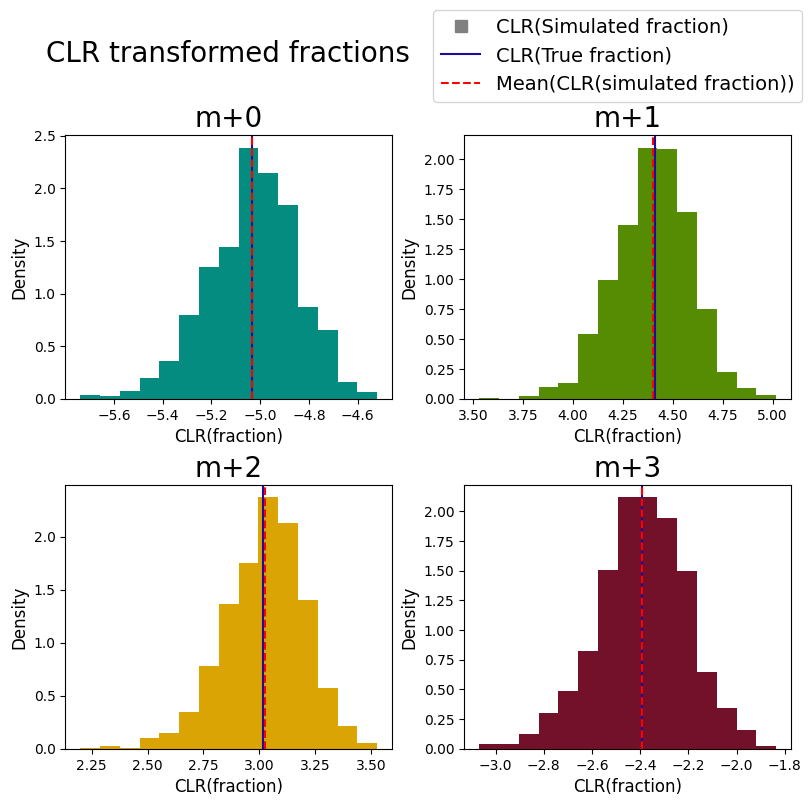

In [132]:
fig_clr, ((ax1_clr, ax2_clr),(ax3_clr,ax4_clr)) = plt.subplots(nrows=2, ncols=2, figsize=(8,8), layout="constrained")
ax1_clr.hist(df_clr["m0_clr"].to_numpy(), bins=15, density=True, label="Simulated m0", color=colors[1])
ax2_clr.hist(df_clr["m1_clr"].to_numpy(), bins=15, density=True, label="Simulated m1", color=colors[2])
ax3_clr.hist(df_clr["m2_clr"].to_numpy(), bins=15, density=True, label="Simulated m2", color=colors[4])
ax4_clr.hist(df_clr["m3_clr"].to_numpy(), bins=15, density=True, label="Simulated m3", color=colors[0])

data_clr=clr_func(data)
ax1_clr.axvline(data_clr[0], color=colors[5], label="True")
ax2_clr.axvline(data_clr[1], color=colors[5], label="True")
ax3_clr.axvline(data_clr[2], color=colors[5], label="True")
ax4_clr.axvline(data_clr[3], color=colors[5], label="True")

ax1_clr.axvline(f123_sim_clr[0], color="red", linestyle="dashed", label="Mean")
ax2_clr.axvline(f123_sim_clr[1], color="red", linestyle="dashed", label="Mean")
ax3_clr.axvline(f123_sim_clr[2], color="red", linestyle="dashed", label="Mean")
ax4_clr.axvline(f123_sim_clr[3], color="red", linestyle="dashed", label="Mean")

ax1_clr.set_title("m+0", size=20)
ax2_clr.set_title("m+1", size=20)
ax3_clr.set_title("m+2", size=20)
ax4_clr.set_title("m+3", size=20)

ax1_clr.set_xlabel("CLR(fraction)", size=12)
ax2_clr.set_xlabel("CLR(fraction)", size=12)
ax3_clr.set_xlabel("CLR(fraction)", size=12)
ax4_clr.set_xlabel("CLR(fraction)", size=12)

ax1_clr.set_ylabel("Density", size=12)
ax2_clr.set_ylabel("Density", size=12)
ax3_clr.set_ylabel("Density", size=12)
ax4_clr.set_ylabel("Density", size=12)

# Custom legend
custom_marker = [
    Line2D([0], [0], color="gray", marker="s", linestyle="", markersize=8),
    Line2D([0], [0], color=colors[5], marker="", linestyle="-", markersize=8),
    Line2D([0], [0], color="red", marker="", linestyle="dashed", markersize=8)
]
fig_clr.legend(custom_marker, ["CLR(Simulated fraction)", "CLR(True fraction)", "Mean(CLR(simulated fraction))"], fontsize=14, loc="outside upper right")

fig_clr.suptitle("CLR transformed fractions", size=20, x=0.05, y=0.95, ha = "left") 

plt.show()

# Estimation of flux with simulated data

## Euclidean space

In [13]:
# Defining initial guess
initial_guess = [100,50]

result_euclidian = optimistix.minimise(objective_wssr, y0=initial_guess, args=(f123_sim, D_sim, v1), solver=solver, max_steps=10000)

v3_est, v5_est = result_euclidian.value
print(v3_est, v5_est)

47.48830638924435 20.601509959041667


In [14]:
v_free_est = jnp.array([v1,v3_est,v5_est]) 
v2_est, v4_est, v6_est = jnp.dot(-M, v_free_est)
v_est = np.array([v1,v2_est,v3_est, v4_est, v5_est, v6_est])
print("Estimated parameters ", v_est)
print("True parameters ", v_true)

Estimated parameters  [100.         106.28528647  47.48830639  20.60150996  20.60150996
  79.39849004]
True parameters  [100 110  50  20  20  80]


In [75]:
ci_euclidean = calc_ci(result_euclidian, confidence_level=0.95)
print(ci_euclidean)

{'params': Array([47.48830639, 20.60150996], dtype=float64), 'standard_errors': Array([561.2301071 ,  36.18196027], dtype=float64), 'ci_bounds': Array([[-1052.50249057,  1147.47910335],
       [  -50.31382907,    91.51684898]], dtype=float64)}


## Aithcison space

In [15]:
# Run optimization
result_clr = optimistix.minimise(objective_clr_wssr, y0=initial_guess, args=(f123_sim_clr, D_sim_clr, v1), solver=solver)
v3_clr, v5_clr = result_clr.value

In [16]:
ci_clr = calc_ci(result_clr, confidence_level=0.95)
print(ci_clr)

{'params': Array([48.61642381, 20.24190765], dtype=float64), 'standard_errors': Array([43.07785405,  7.23520988], dtype=float64), 'ci_bounds': Array([[-35.81461866, 133.04746629],
       [  6.06115687,  34.42265842]], dtype=float64)}


In [17]:
v_free_clr = np.array([v1,v3_clr,v5_clr])
v2_clr, v4_clr, v6_clr = jnp.dot(-M, v_free_clr)
v_clr = np.array([v1,v2_clr,v3_clr,v4_clr,v5_clr,v6_clr])
print("true flux", v_true)
print("Etimated linear", v_est)
print("Estimated compositional", v_clr)

true flux [100 110  50  20  20  80]
Etimated linear [100.         106.28528647  47.48830639  20.60150996  20.60150996
  79.39849004]
Estimated compositional [100.         108.13260852  48.61642381  20.24190765  20.24190765
  79.75809235]


In [18]:
print("Simulated data: \n", np.round(f123_sim,4), "\n")
print("True data: \n", np.round(data,4), "\n")
print("Linear: \n", np.round(simple_net(parameters=np.array([v3_est, v5_est]), v1=v1),4), "\n")
print("Compositional: \n", np.round(simple_net(parameters=np.array([v3_clr, v5_clr]), v1=v1),4), "\n")

Simulated data: 
 [1.000e-04 7.933e-01 2.057e-01 9.000e-04] 

True data: 
 [1.000e-04 8.008e-01 1.983e-01 9.000e-04] 

Linear: 
 [1.000e-04 7.933e-01 2.057e-01 9.000e-04] 

Compositional: 
 [1.000e-04 7.976e-01 2.015e-01 9.000e-04] 

